In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps

import jlinops


import sys
import os

# Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..', ".."))
# sys.path.append(three_dirs_up)



from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])








from msolver import MMGKS, IASGKS, VanillaGKS
from fsolver import MMFGK, IASFGK
from pgkbsolver import MMGKB, IASGKB

#from pinv import CGWeightedNeumann2DPinvOperatorGPU

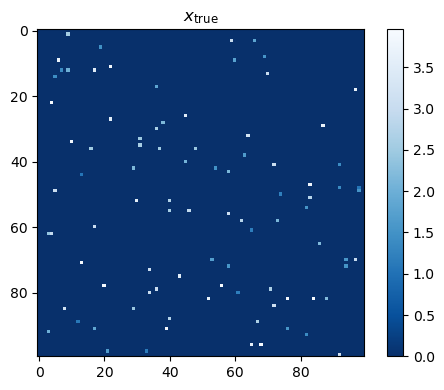

In [20]:
# Set example size
M, N = 100, 100
img_shape = (M,N)
n = M*N

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
ground_truth = (p*q).flatten()
x_true = ground_truth.copy()

plt.figure(figsize=(5,4))
plt.imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.tight_layout()
plt.show()

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_43839/440314591.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


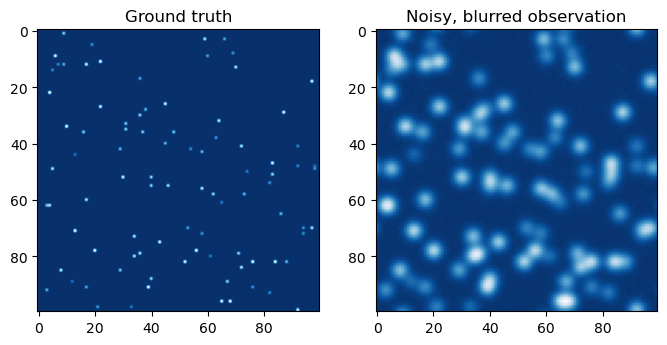

In [21]:
# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0)

# Generate synthetic data
np.random.seed(0)
b_true = A @ ground_truth
noise_sigma = 0.1
b = b_true + noise_sigma*np.random.normal(size=A.shape[0])
b_noisy = b.copy()

noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])



# # Blurred image
# blurred_image = A.matvec_shaped(image)

# # Add some noise
# noise_sigma = 0.03*np.amax(blurred_image)
# noise_var = noise_sigma**2
# noisy_image = blurred_image + noise_sigma*np.random.normal(size=image.shape)
# b = noisy_image.flatten()

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(b.reshape(img_shape), cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

# Set up solvers

In [22]:
# Set method
method = "dp"

#Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
#L = jlinops.Neumann2D(img_shape)
L = jlinops.IdentityOperator((n,n))

def Lpinv_factory(w):
    return jlinops.DiagonalOperator(w)

K = None


q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}


# Build solvers
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=None, img_shape=img_shape)
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


# Run all solvers

In [23]:
vdata = gks_solver.solve(n_iter=75, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})


1e-14
1e-14


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
9.194383479263808
46.17483535503653
62.901940121216214
71.96278440200167
79.37798238825837
88.56963751456105
96.59744461530924
100.29228497696602
105.80526047047816
113.16323470031048
116.30563689419317
120.01704528628368
124.4702843919624
127.43852542141784
129.53322544507319
132.19433563403416
133.9936332494562
136.12306111497648
137.99553745300707
140.09819200094967
140.93485448357742
143.1190791834307


In [24]:
data = mmgks_solver.solve(n_iter=75, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

print("Finished S-GKS.")

resdata = mmgks_solver.solve(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

print("Finished restarting S-GKS.")


recdata = mmgks_solver.solve(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

print("Finished recycling S-GKS.")

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=75, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

print("Finished PS-GKS.")

respdata = mmgks_solver.solve_with_priorconditioning(n_iter=150, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01}, restart_dim=5)

print("Finished restarted PS-GKS.")





mmfkdata = mmfk_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


rmmfkdata = mmfk_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



mmgkbdata = mmgkb_solver.solve(n_iter=75, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



Augmented basis with initial guess!


19.902634466783287
18.757342103845133
18.172736365791415
17.516045008827568
16.485677008609972
15.442212038849018
15.120836425140007
14.841707144514084
14.37734447486909
14.080332786530752
13.754974807399044
14.086064586724566
14.160348167514025
14.602695400374042
15.170374944803442
15.530202126574956
16.051081449331924
16.76160516999728
17.0364120233477
17.207387316596407
17.705543513560855
18.14356940166426
19.048337537939474
19.82409244568772
20.069240687370037
19.94256381984736
20.409645927371873
20.709605349090797
21.47696032498648
22.074551882308835
22.626232512915855
23.257668915837517
23.9199688420424
25.016060703348867
25.596208853016634
25.911809528078166
25.990899173683037
25.777076300522214
26.204181982229258
27.06531471289374
27.445648764179616
27.731526289075713
28.72387328260559
29.928784587024364
30.765382652981064
30.636805210754478
29.974881556214903
29.19061952765295
28.337816950869637
28.139401877662426
28.110994098287712
28.505759274212377
28.95350405094662
28.8976

19.902634466783287
18.757342103845133
18.172736365791415
17.516045008827568
16.485677008609972
15.442212038849018
15.120836425140007
14.841707144514084
14.37734447486909
14.33234934406676
36.369875902586536
24.61227893531741
23.91188652738752
23.565284587935018
24.006454201763574
23.717164512858496
22.49883742563344
23.49864687575535
22.596435062800335
24.112970594319282
25.482365005440894
27.51925422076382
26.156738634944467
26.099968939085535
45.54928986676111
27.85643801530625
26.745766551676176
25.7404876356304
25.87766711673493
27.141357008060407
26.71133436239916
28.730616084017438
26.80681381772513
25.362954209630892
26.542600946592344
26.118096881031125
22.13339472533567
22.10073660921627
38.14503132634122
25.795319587873426
27.341593797918346
26.865941080464783
27.087036996387326
28.044564171916516
27.053439084563667
28.25057453999089
28.819681556544605
28.320504998717926
29.741696687180777
31.47456924032159
27.423146716521
27.383855737062433
45.62387278429556
27.3104354994751

19.902634466783287
18.757342103845133
18.172736365791415
17.516045008827568
16.485677008609972
15.442212038849018
15.120836425140007
14.841707144514084
14.37734447486909
14.080332786530752
13.754974807399044
14.086064586724566
14.160348167514025
14.602695400374042
15.170374944803442
15.530202126574956
16.051081449331924
16.76160516999728
17.0364120233477
17.207387316596407
17.705543513560855
18.14356940166426
19.048337537939474
19.82409244568772
20.069240687370037
19.94256381984736
20.409645927371873
20.709605349090797
21.47696032498648
22.074551882308835
22.626232512915855
23.257668915837517
23.9199688420424
25.016060703348867
25.596208853016634
25.911809528078166
25.990899173683037
25.777076300522214
26.204181982229258
27.06531471289374
27.445648764179616
27.731526289075713
28.72387328260559
29.928784587024364
30.765382652981064
30.636805210754478
29.974881556214903
29.19061952765295
28.337816950869637
28.139401877662426
28.110994098287712
28.505759274212377
28.95350405094662
28.8976

1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
Finished PS-GKS.
Augmented basis with initial guess!


...

generating basis...: 100%|██████████| 74/74 [00:00<00:00, 897.25it/s]

1e-06



generating basis...: 100%|██████████| 75/75 [00:00<00:00, 911.20it/s]

1e-06


Finished P-GKB


# Performance

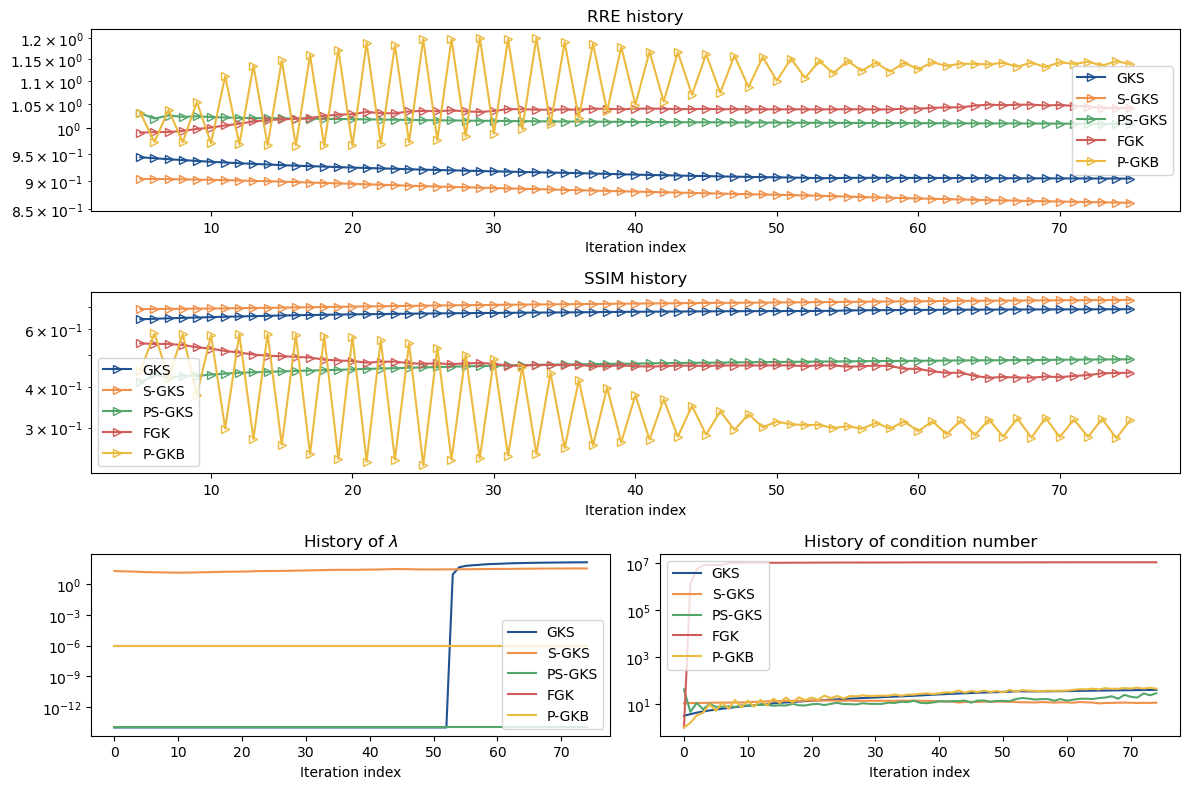

In [25]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_points_performance_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstructions

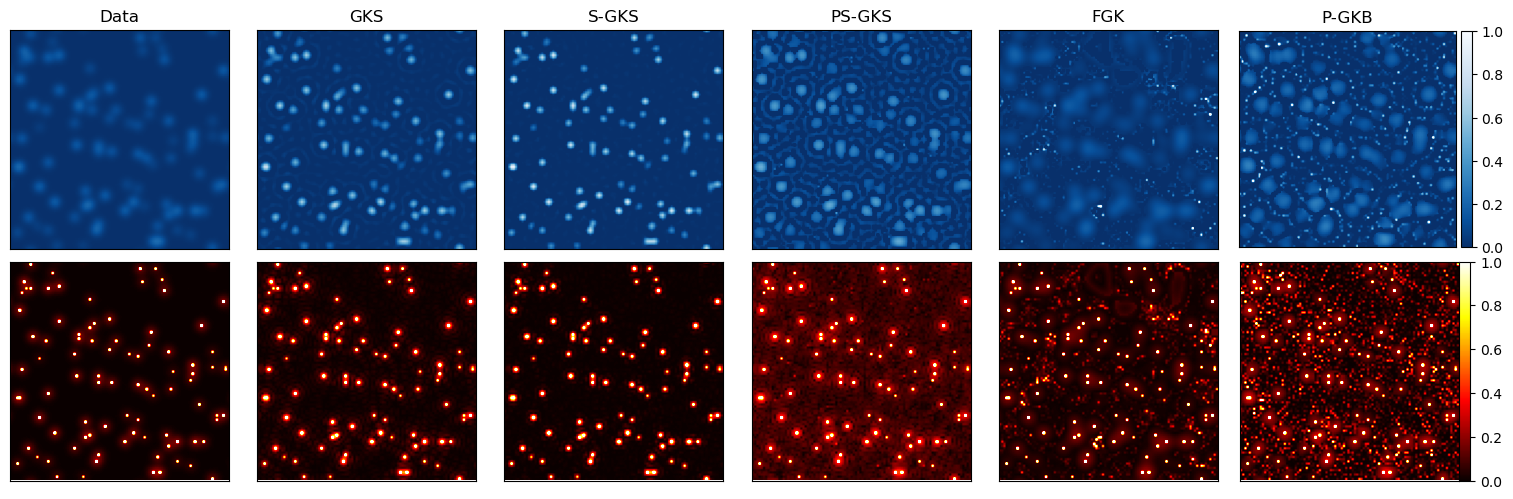

In [32]:
err_cmap = "hot"
plot_cmap = "Blues_r"

vbound = 1.0

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap=plot_cmap, vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_points_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Basis vectors

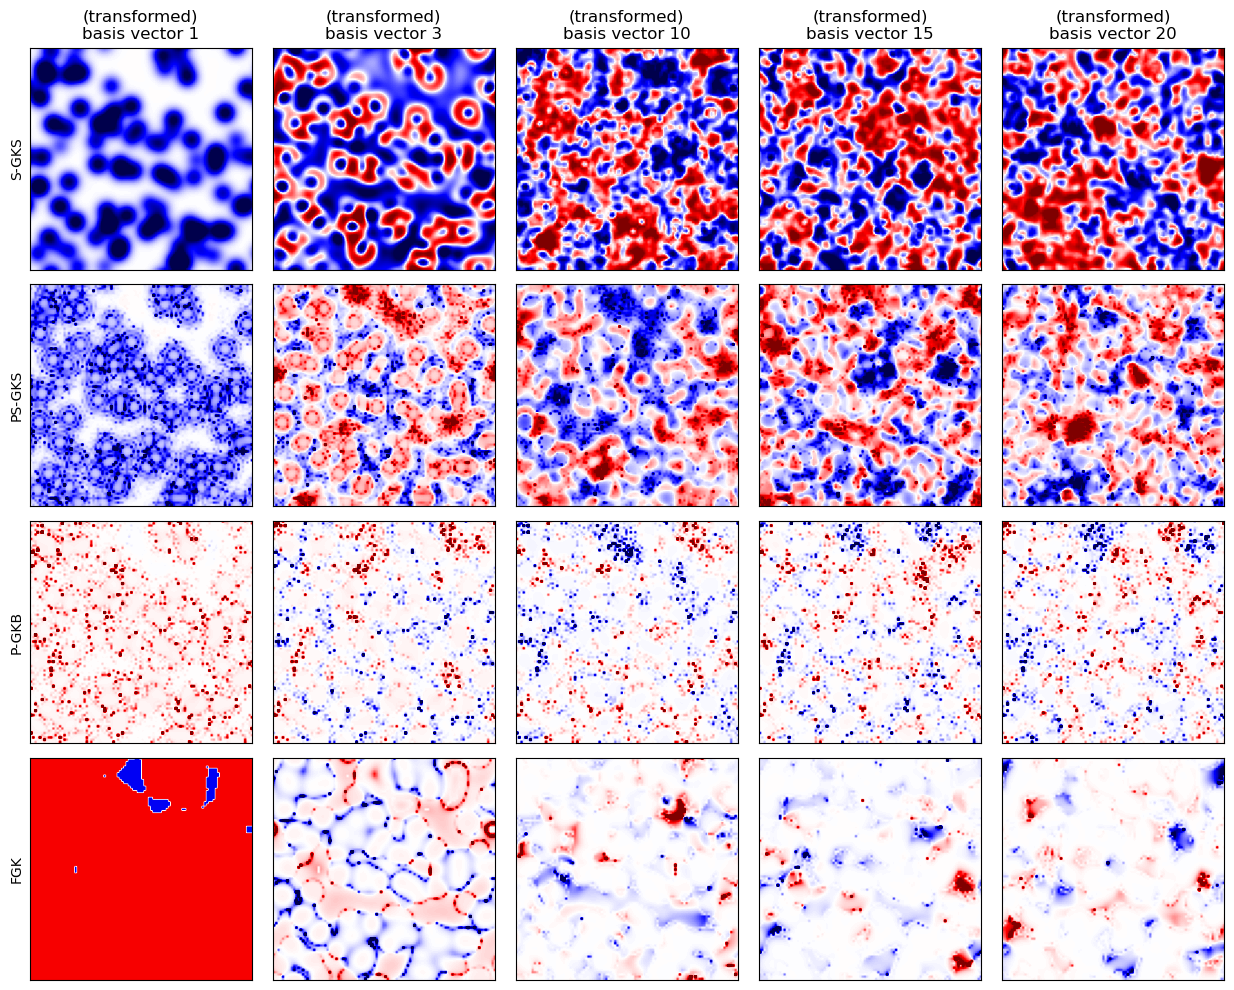

In [33]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_points_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_points_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Old plots

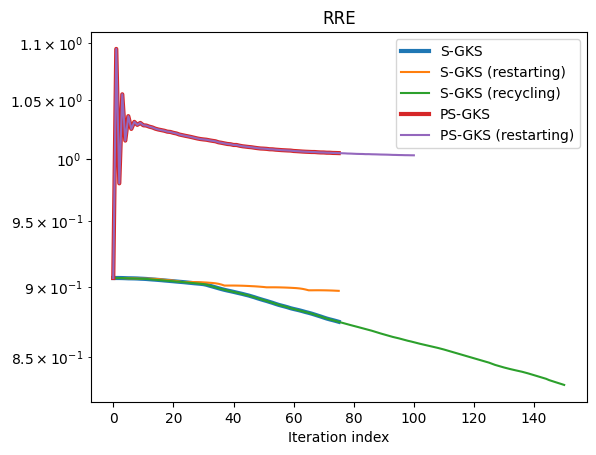

In [43]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS", lw=3)
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)")
plt.semilogy(pdata["rre_history"], label="PS-GKS", lw=3)
plt.semilogy(respdata["rre_history"], label="PS-GKS (restarting)")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

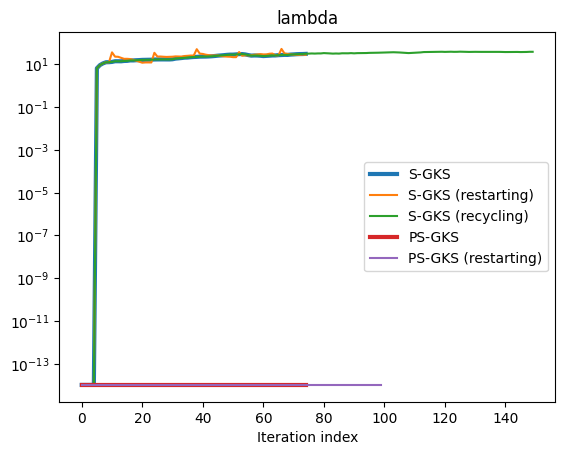

In [44]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS", lw=3)
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", lw=3)
plt.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)")
plt.title("lambda")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

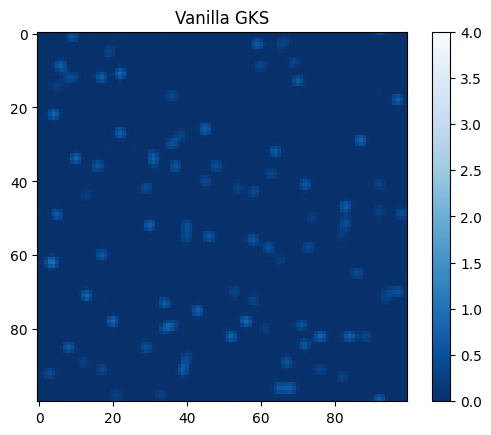

In [45]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

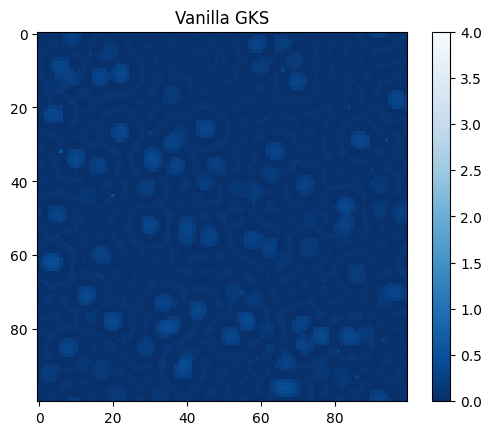

In [46]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

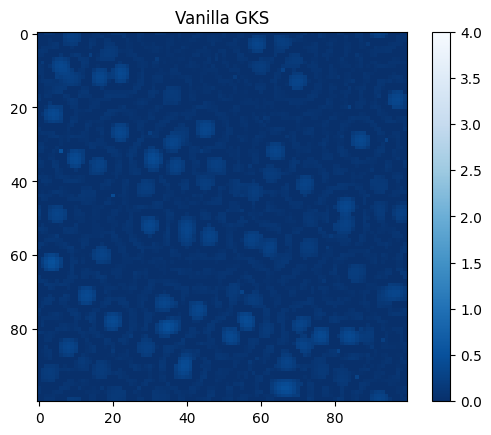

In [47]:
plt.imshow(respdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

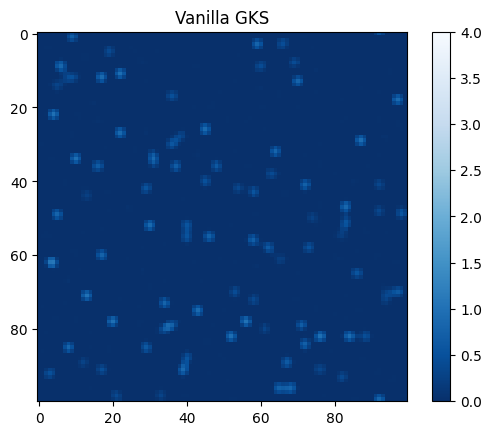

In [48]:
plt.imshow(recdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

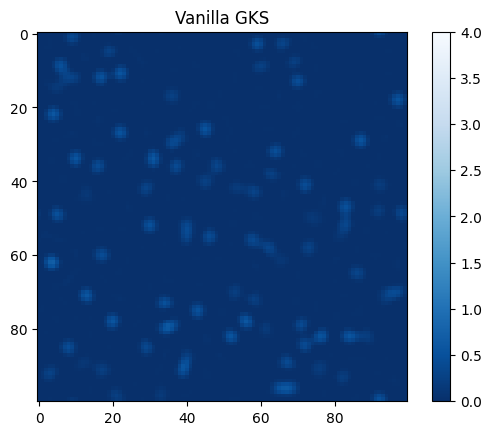

In [37]:
plt.imshow(resdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

# Old

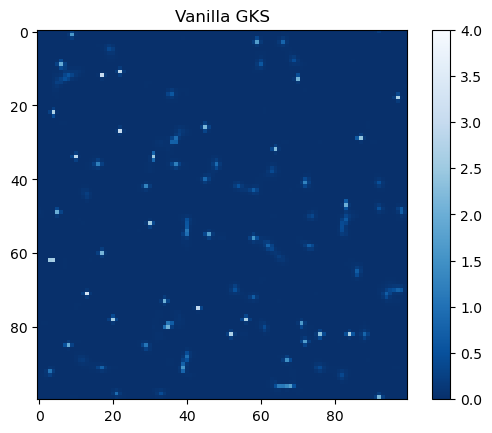

In [23]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

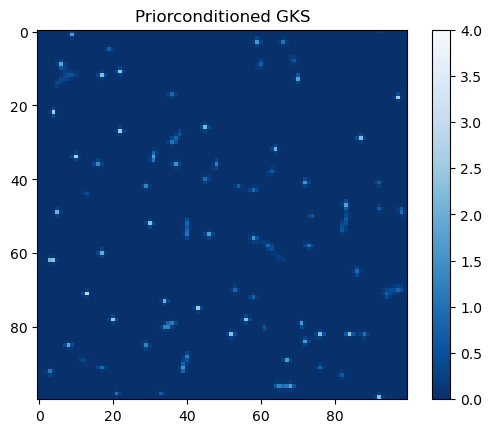

In [29]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

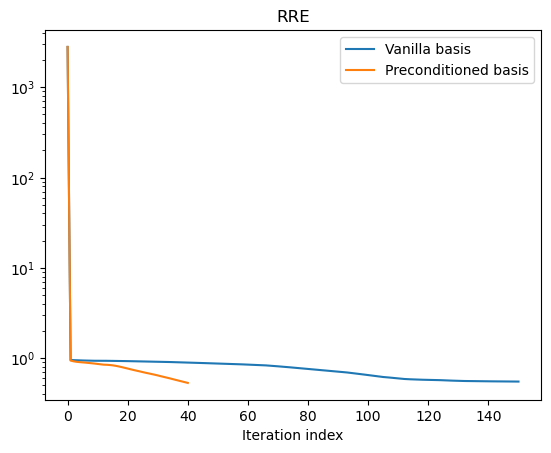

In [27]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

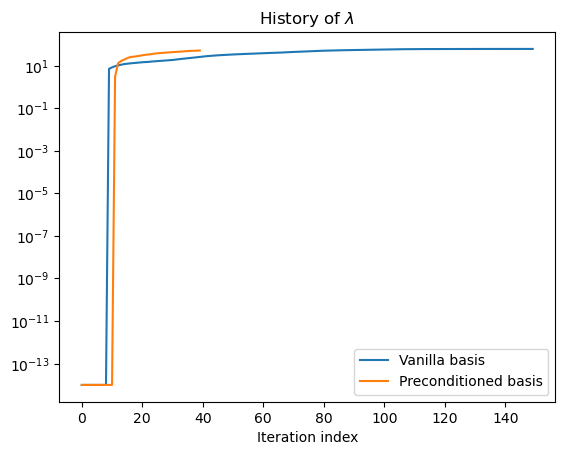

In [26]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

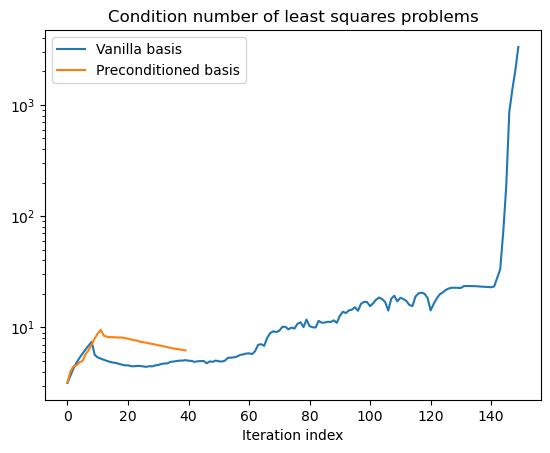

In [25]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# IAS example

In [77]:
n_iters = 200

# weight_params = {
#     "hyperpr_r": 1.0,
#     "hyperpr_beta": 1.5 + 1e-9,
# }

weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [80]:
# Set method
method = "dp"

# Build solver
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [81]:
data = iasgks_solver.solve(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=image.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                                 regparam="dp", x_true=image.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
9.467149935847033
27.118985709168715
45.65587490365957
62.362043251342456
77.59662013253595
92.26863261612445
105.31007822104877
116.12223823864205
124.7868006466447
135.31419179784382
146.85623521033858
160.0401895640133
174.7074343573647
195.75029356445472
231.28069466728147
273.7620994787222
316.57489033725875
364.2742096611241
418.62611109737463
489.29639712301037
537.1812694951551
595.4335665710255
629.1451520584915
645.2171415778886
649.6444334574664
718.9600418002854
744.2526025354924
827.122338413305
861.8415008305542
931.2425012132194
921.9479420670381
1002.0984977847224
1017.4001040720814
994.7871964032231
1078.547984861973
1099.9445920809706
1069.9673805481107
1161.1047683127128
1044.0451718306192
1351.66060160509
853.0075220817574
1091.240119308039
922.4922704970847
1078.8848563445442
1029.0609452813471
951.5734888277361
1010.3324769321263
954.44283372963
1030.0281239186304
965.1086180010684
1004.0394154760099


1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
13.870406721749893
1e-06
24.725919500613795
1e-06
30.49741109612299
53.556704388541895
56.660574954361984
94.46630552345485
144.60342068006463
180.08376256099393
252.09088559241758
301.8974116802701
341.70850329382426
240.8774744674166
72.70196750623187
170.40159679391914
264.0003977389446
260.9680711584005
1e-06
33.80998109026222
78.41403689437186
147.52209551987033
262.1390927504261
480.11986112970294
749.1477577180548
559.3700925891021
1e-06
35.984501928540595
87.72594649760858
180.30731228033918
381.8000762248068
714.9065887148595
709.5286775231243
245.32985494838567
295.5952500382791
292.7938322639731
249.28903575269015
248.00914673448654
289.78829959730916
384.44978488082705
227.37803675872274
471.42888350033354
427.4108350835809
490.09984143192906
266.6074254346446
513.5734149812935
384.2591975448697
698.2042103246083
96.6092536640195
652.694540580394


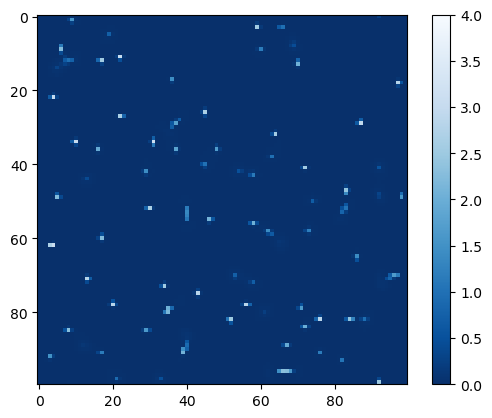

In [82]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

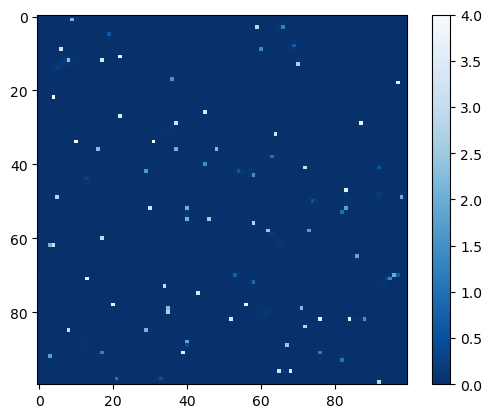

In [83]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

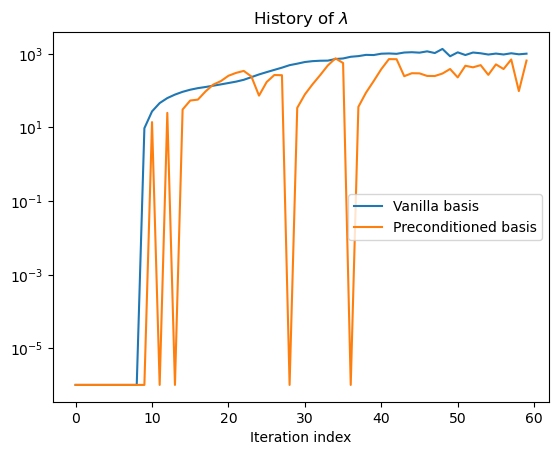

In [84]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

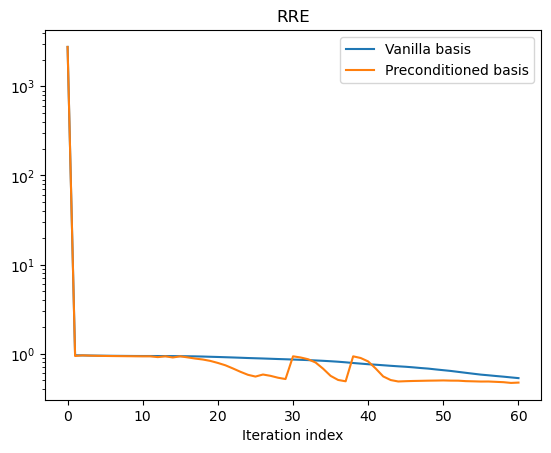

In [85]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()